In [30]:
# Creates a node for the Binary Search Tree

class Node:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None
        
# Initializes a node with a key and no children 

In [84]:
# Creates the Binary Search Tree

class BinarySearchTree:

    # Starts the tree with an empty root
    def __init__(self):
        self.root = None
    
    #Inserts a new key into the correct position
    def insert(self, key):
        if self.root is None:
            self.root = Node(key)
        else: 
            current = self.root
            
            # Moves through the tree to find where they key belongs
            while True:
                if key < current.key:
                    if current.left is None:
                        current.left = Node(key)
                        break
                    else: 
                        current= current.left
                else:
                    if current.right is None:
                        current.right = Node(key)
                        break
                    else:
                        current = current.right
                        
    # Searches for a key and counts the nodes checked                     
    def search(self, key):
        current = self.root
        comparisons = 0 
        
        while current is not None:
            comparisons += 1 
            
            if key == current.key:
                return True, comparisons
            
            elif key < current.key:
                current = current.left
                
            else:
                current = current.right
                
        return False, comparisons
    
    # Visist the nodes in order from the smallest to largest
    def inorder_traversal(self):
        result = []
        
        def traverse(node):
            if node is not None:
                traverse(node.left)
                result.append(node.key)
                traverse(node.right)
                
        traverse(self.root)
        return result
    
    # Finds the maximum depth of the BST without recursion
    def height(self):
        if self.root is None:
            return -1
            
        max_depth = 0
        stack = [(self.root, 0)]
            
        while stack:
            node, depth = stack.pop()
            max_depth = max(max_depth, depth)
            
            if node.left is not None:
                stack.append((node.left, depth + 1))
                
            if node.right is not None:
                stack.append((node.right, depth + 1))
        
        return max_depth
    
    # Finds the depth of every node without recursion
    def node_depths(self):
        depths = {}
        
        if self.root is None:
            return depths
        stack = [(self.root, 0)]
        
        while stack:
            node, depth = stack.pop()
            depths[node.key] = depth
            
            if node.left is not None:
                stack.append((node.left, depth + 1))
                
            if node.right is not None:
                stack.append((node.right, depth + 1))
                
        return depths
                

In [85]:
bst = BinarySearchTree()

keys = [50, 30, 70, 20, 40, 60, 80, 35, 45]

for key in keys:
    bst.insert(key)

print(bst.root.key)
print(bst.root.left.key)
print(bst.root.right.key)
print(bst.root.left.right.key)
print(bst.root.left.right.left.key)
print(bst.root.left.right.right.key)

50
30
70
40
35
45


In [86]:
print(bst.search(35))
print(bst.search(60))
print(bst.search(80))

(True, 4)
(True, 3)
(True, 3)


In [87]:
print(bst.inorder_traversal())

[20, 30, 35, 40, 45, 50, 60, 70, 80]


In [88]:
print(bst.height())

3


In [89]:
print(bst.node_depths())

{50: 0, 70: 1, 80: 2, 60: 2, 30: 1, 40: 2, 45: 3, 35: 3, 20: 2}


In [90]:
# Part 2: Ascending insertion order with 100 nodes 
 
N = 100

ascending_bst = BinarySearchTree()

for key in range(1, N + 1):
    ascending_bst.insert(key)
    
print("Tree height:", ascending_bst.height())

Tree height: 99


In [91]:
# Calculate the average node depth for ascending insertion

depths = ascending_bst.node_depths()

average_depth = sum(depths.values()) / len(depths)

print("Average node depth:", average_depth)

Average node depth: 49.5


In [92]:
# Calculate average successful search comparisons 

total_comparisons = 0

for key in range(1, N + 1):
    found, comparisons = ascending_bst.search(key)
    total_comparisons += comparisons
    
average_comparisons = total_comparisons / N

print("Average search comparisons:", average_comparisons)

Average search comparisons: 50.5


In [93]:
print(bst.height())

3


In [94]:
print(bst.node_depths())

{50: 0, 70: 1, 80: 2, 60: 2, 30: 1, 40: 2, 45: 3, 35: 3, 20: 2}


In [95]:
print(sum(ascending_bst.node_depths().values()) / 100)

49.5


In [97]:
# Test ascending insertion for different tree sizes 

sizes = [100, 500, 1000, 2000]

ascending_results = []

for N in sizes:
    ascending_bst = BinarySearchTree()
    
    # Insert keys in ascending order
    for key in range(1, N + 1):
        ascending_bst.insert(key)
        
    # Calculate tree height
    tree_height = ascending_bst.height()
    
    # Caclulate avearge node depth 
    depths = ascending_bst.node_depths()
    average_depth = sum(depths.values()) / N
    
    # Calculate average successful search commparisons
    total_comparisons = 0 
    
    for key in range(1, N + 1):
        found, comparisons = ascending_bst.search(key)
        total_comparisons += comparisons 
        
    average_comparisons = total_comparisons / N
    
    # Save the results
    ascending_results.append(
        (N, tree_height, average_depth, average_comparisons)
    )
    
    print(N, tree_height, average_depth, average_comparisons)

100 99 49.5 50.5
500 499 249.5 250.5
1000 999 499.5 500.5
2000 1999 999.5 1000.5


In [98]:
# Part 2: Random insertion order with 100 nodes

import random

N = 100

keys = list(range(1, N + 1))

random.seed(1)
random.shuffle(keys)

random_bst = BinarySearchTree()

for key in keys:
    random_bst.insert(key)
    
print("Tree height:", random_bst.height())

Tree height: 11


In [100]:
# Calculate average node depth for random insertion 

depths = random_bst.node_depths()

average_depth = sum(depths.values()) / len(depths)

print("Average node depth:", average_depth)

Average node depth: 6.13


In [101]:
# Calculate average successful search comparisons for random insertion 

total_comparisons = 0 

for key in range(1, N +1):
    found, comparisons = random_bst.search(key)
    total_comparisons += comparisons
    
average_comparisons = total_comparisons / N

print("Average search comparisons:", average_comparisons)

Average search comparisons: 7.13


In [104]:
# Test random insertion for different tree sizes 

sizes = [100, 500, 1000, 2000]

random_results = []

for N in sizes:
    keys = list(range(1, N + 1))
    random.shuffle(keys)
    
    random_bst = BinarySearchTree()
    
    for key in keys:
        random_bst.insert(key)
        
    # Calculate tree height 
    tree_height = random_bst.height()
    
    # Calculate average node depth
    depths = random_bst.node_depths()
    average_depth = sum(depths.values()) / N
    
    # Calculate average successful search comparisons
    total_comparisons = 0
    
    for key in range(1, N + 1):
        found, comparisons = random_bst.search(key)
        total_comparisons += comparisons
        
    average_comparisons = total_comparisons / N
    
    # Save results
    random_results.append(
        (N, tree_height, average_depth, average_comparisons)
    )
    
    print(N, tree_height, average_depth, average_comparisons)

    

100 12 6.58 7.58
500 18 10.238 11.238
1000 22 10.939 11.939
2000 24 11.8705 12.8705


In [106]:
# Run 10 random trials for each tree size 

sizes = [100, 500, 1000, 2000]
trial_results = []

for N in sizes:
    for trial in range(10): 
        keys = list(range(1, N +1))
        random.shuffle(keys)
        
        random_bst = BinarySearchTree()
        
        for key in keys:
            random_bst.insert(key)
            
        tree_height = random_bst.height()
        
        depths = random_bst.node_depths()
        average_depth = sum(depths.values()) / N
        
        total_comparisons = 0
        
        for key in range(1, N + 1):
            found, comparisons = random_bst.search(key)
            total_comparisons += comparisons
            
        average_comparisons = total_comparisons / N
        
        trial_results.append(
            (N, trial + 1, tree_height, average_depth, average_comparisons)
        )
        
        print(N, trial + 1, tree_height, average_depth, average_comparisons)

100 1 14 6.29 7.29
100 2 14 7.54 8.54
100 3 13 6.3 7.3
100 4 16 7.99 8.99
100 5 12 6.18 7.18
100 6 14 6.54 7.54
100 7 11 6.27 7.27
100 8 10 5.73 6.73
100 9 12 6.2 7.2
100 10 11 6.57 7.57
500 1 18 10.928 11.928
500 2 17 9.65 10.65
500 3 17 9.364 10.364
500 4 17 9.814 10.814
500 5 17 9.32 10.32
500 6 20 9.878 10.878
500 7 17 9.408 10.408
500 8 15 8.594 9.594
500 9 19 8.94 9.94
500 10 19 9.422 10.422
1000 1 19 10.641 11.641
1000 2 20 10.696 11.696
1000 3 19 10.131 11.131
1000 4 22 11.094 12.094
1000 5 18 10.537 11.537
1000 6 20 10.95 11.95
1000 7 21 11.297 12.297
1000 8 24 11.099 12.099
1000 9 23 11.588 12.588
1000 10 26 11.82 12.82
2000 1 24 12.287 13.287
2000 2 29 12.177 13.177
2000 3 23 12.009 13.009
2000 4 23 11.5755 12.5755
2000 5 26 13.214 14.214
2000 6 24 13.31 14.31
2000 7 22 11.973 12.973
2000 8 22 11.707 12.707
2000 9 22 12.245 13.245
2000 10 23 12.2455 13.2455


In [109]:
# Calculate averages across the 10 random trials

for N in sizes:
    results = [row for row in trial_results if row[0] == N]
    
    avg_height = sum(row[2] for row in results) / len(results)
    avg_depth = sum(row[3] for row in results) / len(results)
    avg_comparisons = sum(row[4] for row in results) / len(results)
    
    print(N, round(avg_height, 2), round(avg_depth, 2), round(avg_comparisons, 2))

100 12.7 6.56 7.56
500 17.6 9.53 10.53
1000 21.2 10.99 11.99
2000 23.8 12.27 13.27


In [110]:
# Create an insertion order that keeps the BST balanced
def balanced_order(keys):
    if not keys:
        return []

    middle = len(keys) // 2

    return (
        [keys[middle]]
        + balanced_order(keys[:middle])
        + balanced_order(keys[middle + 1:])
    )

# Test with 7 keys
print(balanced_order(list(range(1, 8))))


[4, 2, 1, 3, 6, 5, 7]


In [111]:
# Part 2C: Balanced insertion order with 100 nodes

N = 100

keys = list(range(1, N + 1))

# Find the balanced insertion order
order = balanced_order(keys)

# Create a new BST
balanced_bst = BinarySearchTree()

# Insert keys in balanced order
for key in order:
    balanced_bst.insert(key)

# Calculate tree height
print("Tree height:", balanced_bst.height())


Tree height: 6


In [112]:
# Calculate average node depth for balanced insertion

depths = balanced_bst.node_depths()

average_depth = sum(depths.values()) / len(depths)

print("Average node depth:", average_depth)


Average node depth: 4.8


In [113]:
# Calculate average successful search comparisons for balanced insertion

total_comparisons = 0

for key in range(1, N + 1):
    found, comparisons = balanced_bst.search(key)
    total_comparisons += comparisons

average_comparisons = total_comparisons / N

print("Average search comparisons:", average_comparisons)


Average search comparisons: 5.8


In [114]:
# Part 2C: Test balanced insertion for different tree sizes

sizes = [100, 500, 1000, 2000]

balanced_results = []

for N in sizes:
    keys = list(range(1, N + 1))
    order = balanced_order(keys)

    balanced_bst = BinarySearchTree()

    for key in order:
        balanced_bst.insert(key)

    # Calculate tree height
    tree_height = balanced_bst.height()

    # Calculate average node depth
    depths = balanced_bst.node_depths()
    average_depth = sum(depths.values()) / N

    # Calculate average successful search comparisons
    total_comparisons = 0

    for key in range(1, N + 1):
        found, comparisons = balanced_bst.search(key)
        total_comparisons += comparisons

    average_comparisons = total_comparisons / N

    # Save results
    balanced_results.append(
        (N, tree_height, average_depth, average_comparisons)
    )

    print(N, tree_height, average_depth, average_comparisons)


100 6 4.8 5.8
500 8 6.996 7.996
1000 9 7.987 8.987
2000 10 8.982 9.982


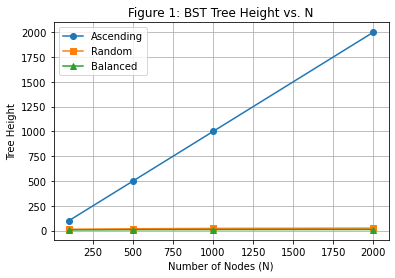

In [115]:
# Figure 1: Tree Height vs. N

import matplotlib.pyplot as plt

sizes = [100, 500, 1000, 2000]

# Heights from ascending insertion
ascending_heights = [row[1] for row in ascending_results]

# Heights from balanced insertion
balanced_heights = [row[1] for row in balanced_results]

# Average heights from 10 random trials
random_heights = []

for N in sizes:
    results = [row for row in trial_results if row[0] == N]
    avg_height = sum(row[2] for row in results) / len(results)
    random_heights.append(avg_height)

# Plot the three insertion strategies
plt.plot(sizes, ascending_heights, marker='o', label='Ascending')
plt.plot(sizes, random_heights, marker='s', label='Random')
plt.plot(sizes, balanced_heights, marker='^', label='Balanced')

plt.xlabel('Number of Nodes (N)')
plt.ylabel('Tree Height')
plt.title('Figure 1: BST Tree Height vs. N')
plt.legend()
plt.grid(True)

plt.show()


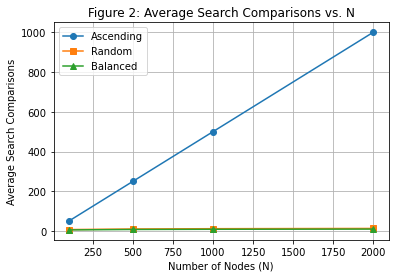

In [116]:

# Figure 2: Average Search Comparisons vs. N

import matplotlib.pyplot as plt

sizes = [100, 500, 1000, 2000]

# Average comparisons for ascending insertion
ascending_comparisons = [row[3] for row in ascending_results]

# Average comparisons for balanced insertion
balanced_comparisons = [row[3] for row in balanced_results]

# Average comparisons across 10 random trials
random_comparisons = []

for N in sizes:
    results = [row for row in trial_results if row[0] == N]
    avg_comparisons = sum(row[4] for row in results) / len(results)
    random_comparisons.append(avg_comparisons)

# Plot the three insertion strategies
plt.plot(sizes, ascending_comparisons, marker='o', label='Ascending')
plt.plot(sizes, random_comparisons, marker='s', label='Random')
plt.plot(sizes, balanced_comparisons, marker='^', label='Balanced')

plt.xlabel('Number of Nodes (N)')
plt.ylabel('Average Search Comparisons')
plt.title('Figure 2: Average Search Comparisons vs. N')
plt.legend()
plt.grid(True)

plt.show()


1. Which insertion strategy produces the tallest BST? Explain why.
Ascending insertion producest the tallest BST becasue the keys are inserted from smallest to largest. Since each new key is greater than the previous key, it is always inserted to the right. This causes the BST to grow into a straight chain instead of branching into left and right subtrees. In my experiment, when N = 2000, the ascending BST had a height of 1999, whiel the random BST had an average height of 23.8 and the balanced BST had a height of 10. This shows that ascending insertion produces the tallest tree because the nodes are not distributed evenly. 

2. How does the height of the BST change as N increases for each strategy? Relate your observations to the theoretical time complexity of BST operations.
As N increases, the height of the BST increases differently depending on the insertion strategy. For ascending insertion, the height increases directly with N because every new node is added to the right, creating a chain. This resulsts in O(N) time commplexity for searching in the worst case. For random insertion, the height increases much more slowly because the nodes are distributed across different branches, although the tree is not guaranteed to be balanced. Random insertion generally has O(logN) expected search time. Balanced insertion produces the shortest trees because the keys are inserted in an order that keeps the left and right subtrees approximately balanced. This results in O(logN) search time. My experiments showed that when N increased from 100 to 2000, the ascending tree height increased from 99 to 1999, while the balanced tree height only increased from 6 to 10. 

3. Compare the average successful search comparisons across the three strategies. How closely do these results correspond to the tree heights?
The average number of successful search comparisons was highest for ascending insertion, followed by random insertion, and lowest for balanced insertion. This is because taller trees generally require more comparisons to find a key. In my experiment with N = 2000, ascending insertion required an average of 1000.5 comparisons, random insertion required 13.27, and balanced insertion required 9.98. The ascending BST required significantly more commparisons because the nodes formed a long chain. Random insertion required fewer comparisons because the tree had shorter paths, while balanced insertion required the fewest because its nodes were distributed more evenly. These results show that tree height is related to search performance, although the average depth of all nodes determines the exact average number of comparisons. 

4. Is a BST constructed using random insertion necessarily balanced? Explain based on your experiments.
No, a BST constructed using random insertion is not necessarily balanced. Random insertion places keys in a shuffed order, which usually creates a shorter tree than ascending insertion. However, random insertion does not guarantee that the left and right subtrees will have similar heights. Some brances may still become longer than others. In my experiment with N = 1000, the random BST had an average height of 21.1 across 10 trialsm while the balanced BST had a height of 9. This shows that random insertion can produce a relatively efficient BST, but it does not gurantee the smallest possible height. Balanced insertion is more consistent because it intentionally selects middle keys to keep the tree height small. 

In [117]:
# Part 3: Create three BSTs with 1000 nodes

N = 1000

# Create an ascending BST
ascending_tree = BinarySearchTree()

for key in range(1, N + 1):
    ascending_tree.insert(key)

# Create a random BST using a fixed seed
import random

random.seed(42)
keys = list(range(1, N + 1))
random.shuffle(keys)

random_tree = BinarySearchTree()

for key in keys:
    random_tree.insert(key)

# Create a balanced BST
balanced_tree = BinarySearchTree()

keys = list(range(1, N + 1))
order = balanced_order(keys)

for key in order:
    balanced_tree.insert(key)

# Check the heights of all three trees
print("Ascending height:", ascending_tree.height())
print("Random height:", random_tree.height())
print("Balanced height:", balanced_tree.height())


Ascending height: 999
Random height: 20
Balanced height: 9


In [118]:
# Part 3: Collect node depths for all three BSTs

# Get the depth of every node in each tree
ascending_depths = ascending_tree.node_depths()
random_depths = random_tree.node_depths()
balanced_depths = balanced_tree.node_depths()

# Check the number of nodes in each tree
print("Ascending nodes:", len(ascending_depths))
print("Random nodes:", len(random_depths))
print("Balanced nodes:", len(balanced_depths))


Ascending nodes: 1000
Random nodes: 1000
Balanced nodes: 1000


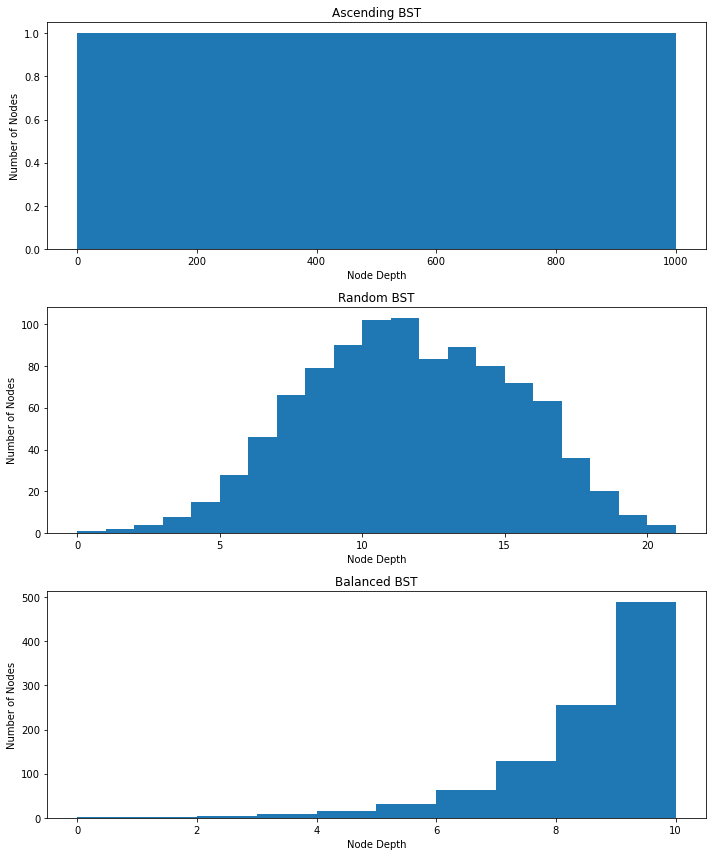

In [119]:
# Part 3: Figure 3 - Node-Depth Distribution

import matplotlib.pyplot as plt

# Convert node depths into lists
ascending_values = list(ascending_depths.values())
random_values = list(random_depths.values())
balanced_values = list(balanced_depths.values())

# Create three histograms
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

# Ascending BST
axes[0].hist(ascending_values, bins=range(1001))
axes[0].set_title("Ascending BST")
axes[0].set_xlabel("Node Depth")
axes[0].set_ylabel("Number of Nodes")

# Random BST
axes[1].hist(random_values, bins=range(22))
axes[1].set_title("Random BST")
axes[1].set_xlabel("Node Depth")
axes[1].set_ylabel("Number of Nodes")

# Balanced BST
axes[2].hist(balanced_values, bins=range(11))
axes[2].set_title("Balanced BST")
axes[2].set_xlabel("Node Depth")
axes[2].set_ylabel("Number of Nodes")

plt.tight_layout()
plt.show()


1. How do the node-depth distributions differ among the three insertion strategies?
When I compared the node-depth distributions, I noticed that each insertion strategy produced a different result. For ascending insertion, the nodes were spread across depths 0 to 999, with only one node at each depth. This happened because the tree formed a straight chain instead of branching out. For random insertion, most of the nodes were grouped around the middle depths, and the deepest node was at depth 20. This shows that random insertion created more branches instead of one long chain. For balanced insertion, most of the nodes were around depths 8 and 9, with a maximum depth of 9. From these results, I noticed that balanced insertion kept the tree much shorter, while ascending insertion created the deepest tree.

2. Why might two BSTs with similar heights have different average search performance?
Two BSTs can have similar heights but still have different average search performance because height only tells us how deep the tree goes, not where all the nodes are located. For example, one tree might have most of its nodes closer to the root, while another might have more nodes farther down. Since searching starts at the root, nodes that are closer require fewer comparisons to find. This means that even if two trees have the same height, the tree with a lower average node depth will usually have better search performance when all keys are searched equally often.

3. Explain the relationship between average node depth and average successful search comparisons. Can you express this relationship mathematically for a BST containing N distinct keys, assuming each key is searched exactly once?
From my results, I noticed that average node depth and average successful search comparisons are closely related. When searching for a key in a BST, the search starts at the root and makes a comparison at each node until the key is found. Since the root starts at depth 0 but still needs one comparison, the number of comparisons is always the node's depth plus 1. This means that the average number of successful search comparisons is equal to the average node depth plus 1, which can be written as C_avg = D_avg + 1 when each key is searched exactly once. For example, in my experiment with 100 nodes, the balanced BST had an average node depth of 4.8 and an average of 5.8 comparisons. This matched the formula and helped me understand how node depth affects search performance.